# PPMI Protein PCs and Progression

Baseline CSF protein principal components prediction of motor progression beyond clinical variables and established biomarkers

In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

data_path = Path("../../data/processed/ppmi_csf_corrected.csv")
source = "harmonized_olink_csf_src"
outcome = "slope_updrs3_off"

candidates = ["age_at_visit", "SEX", "duration_yrs", "updrs3_score", "LEDD", "MIA_PUTAMEN_BILAT", "CSFSAA", source]
metadata = ["PATNO", "EVENT_ID", "COHORT", outcome, "updrs1_score", "updrs2_score"] + candidates
header = pd.read_csv(data_path, nrows=0).columns
proteins = [column for column in header if column.startswith("harmonized_olink_csf_") and column.endswith("_NPX")]
data = pd.read_csv(data_path, usecols=metadata + proteins, low_memory=False)

## Participants

Use PD participants with baseline CSF proteins and an available progression slope. Each participant contributes one row.

In [32]:
csf_baseline = data[(data["EVENT_ID"] == "BL") & data[source].notna()]
pd_baseline = csf_baseline[csf_baseline["COHORT"] == 1]
sample = pd_baseline[pd_baseline[outcome].notna()].reset_index(drop=True).copy()

print("PD participants with baseline CSF proteins:", len(pd_baseline))
print("With a progression slope:", len(sample))
print("Without a progression slope:", len(pd_baseline) - len(sample))

PD participants with baseline CSF proteins: 938
With a progression slope: 819
Without a progression slope: 119


## Variable definitions

From the PPMI Project 9004 data dictionary:

- `slope_updrs3_off`: OLS slope of `updrs3_score` over `YEAR`. Units are points per year.
- `updrs3_score`: UPDRS III Score, scored OFF medication or untreated.
- `CSFSAA`: CSF α-synuclein seed amplification assay. 0 = negative, 1 = positive (Lewy body-like), 2 = inconclusive, 3 = positive (MSA-like).
- `MIA_PUTAMEN_BILAT`: DaTscan bilateral putamen binding ratio. Lower values indicate more dopamine transporter loss.
- `LEDD`: total levodopa equivalent daily dose at the visit.
- `age_at_visit`, `SEX`, `duration_yrs`, and protein source project.

## Progression rates

Positive slopes mean increasing motor scores (worse), while negative slopes mean decreasing scores.

In [33]:
sample[outcome].describe().rename("UPDRS 3 points/year").round(2).to_frame()

,UPDRS 3 points/year
count,819.00
mean,2.18
std,4.63
min,-22.00
25%,0.05
50%,1.64
75%,3.93
max,32.00


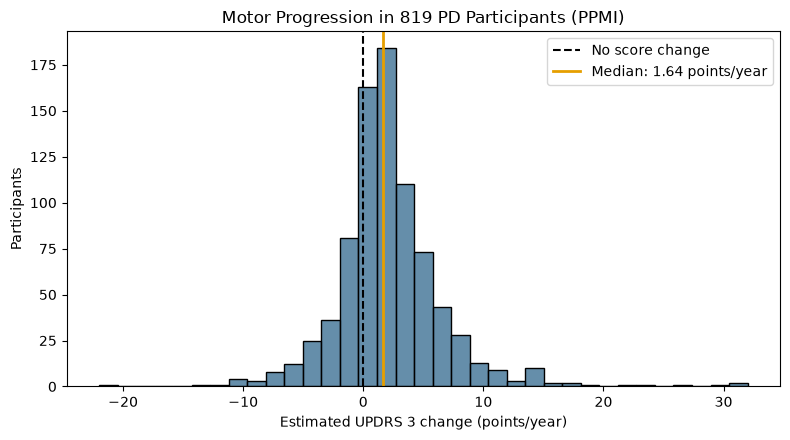

In [34]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=sample, x=outcome, bins=35, color="#31688e")
plt.axvline(0, color="black", linestyle="--", label="No score change")
plt.axvline(sample[outcome].median(), color="#e69f00", linewidth=2,
            label=f"Median: {sample[outcome].median():.2f} points/year")
plt.xlabel("Estimated UPDRS 3 change (points/year)")
plt.ylabel("Participants")
plt.title(f"Motor Progression in {len(sample)} PD Participants (PPMI)")
plt.legend()
plt.tight_layout()
plt.show()

## Baseline variables

Age, sex, disease duration, motor score, medication dose (LEDD), DaTscan, SAA, and source project are used in the reference model. Missing values are filled with the median.

In [35]:
numeric = ["age_at_visit", "SEX", "duration_yrs", "updrs3_score", "LEDD", "MIA_PUTAMEN_BILAT"]
summary = sample[numeric].describe().T[["count", "mean", "std"]]
summary["Missing (%)"] = sample[numeric].isna().mean() * 100
summary.round(2)

,count,mean,std,Missing (%)
age_at_visit,819.0,62.30,9.49,0.00
SEX,819.0,0.63,0.48,0.00
duration_yrs,819.0,1.05,1.36,0.00
updrs3_score,810.0,22.09,9.79,1.10
LEDD,819.0,74.77,237.32,0.00
MIA_PUTAMEN_BILAT,806.0,0.73,0.25,1.59


In [36]:
sample["saa_result"] = sample["CSFSAA"].map({0: "Negative", 1: "Positive"}).fillna("Other or unknown")
sample["source_project"] = sample[source].map({"p314_CSF": "Project 314", "p277_CSF_corrected": "Project 277"})
sample["dat_group"] = pd.qcut(sample["MIA_PUTAMEN_BILAT"], 4, labels=["0.10–0.56", "0.57–0.70", "0.71–0.87", "0.88–1.80"])

print("Missing DaTscan:", sample["MIA_PUTAMEN_BILAT"].isna().sum())
print("LEDD = 0:", round((sample["LEDD"] == 0).mean() * 100, 1))

Missing DaTscan: 13
LEDD = 0: 85.5


## Biomarkers and progression

Compare progression by SAA result and by DaTscan groups.

SAA positive means Lewy body-like positive. DaTscan is grouped only for this figure, the model uses a continuous value.

In [37]:
sample.groupby("saa_result")[outcome].agg(["count", "median"]).round(2)

,count,median
saa_result,,
Negative,84,1.50
Other or unknown,13,4.68
Positive,722,1.65


In [38]:
sample.groupby("dat_group", observed=True)[outcome].agg(["count", "median"]).round(2)

,count,median
dat_group,,
0.10–0.56,220,1.82
0.57–0.70,194,1.60
0.71–0.87,193,1.86
0.88–1.80,199,1.57


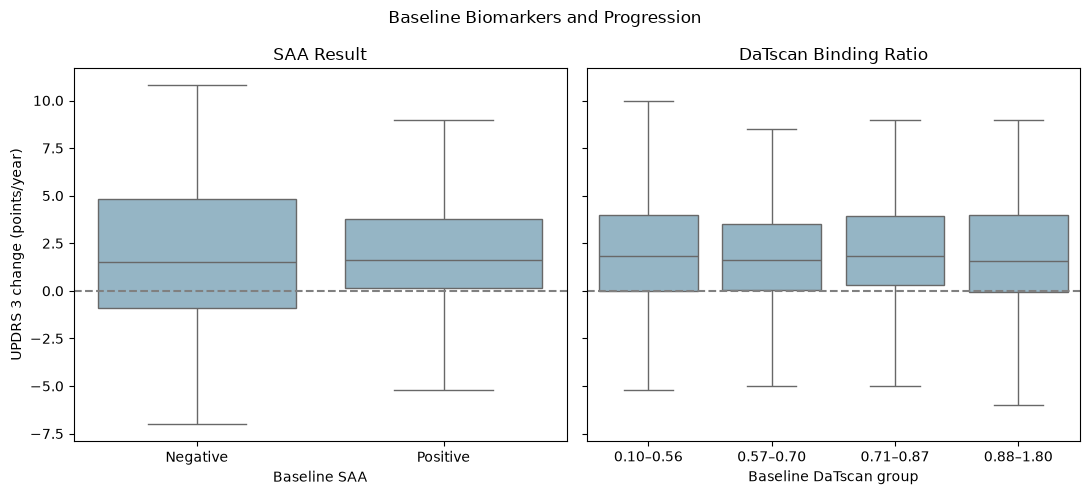

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

sns.boxplot(data=sample, x="saa_result", y=outcome,
            order=["Negative", "Positive"], color="#8db8cd", showfliers=False, ax=axes[0])
axes[0].set_title("SAA Result")
axes[0].set_xlabel("Baseline SAA")

sns.boxplot(data=sample, x="dat_group", y=outcome,
            color="#8db8cd", showfliers=False, ax=axes[1])
axes[1].set_title("DaTscan Binding Ratio")
axes[1].set_xlabel("Baseline DaTscan group")

for ax in axes:
    ax.axhline(0, color="grey", linestyle="--")
    ax.set_ylabel("UPDRS 3 change (points/year)")

plt.suptitle("Baseline Biomarkers and Progression")
plt.tight_layout()
plt.show()

## Prediction models

1. **Mean:** average progression slope.
2. **Reference without UPDRS 3:** the clinical and biomarker model with baseline motor score removed.
3. **Reference:** clinical variables, SAA, DaTscan, and source project.
4. **Reference + PCs:** the same variables plus three protein PCs.

We use three PCs to continue the earlier PCA analysis. SAA and source project are encoded as 0/1 columns, negative SAA and Project 314 are the reference categories.

In [40]:
clinical = sample[numeric].copy()
clinical["SAA positive"] = (sample["saa_result"] == "Positive").astype(int)
clinical["SAA other or unknown"] = (sample["saa_result"] == "Other or unknown").astype(int)
clinical["Project 277"] = (sample["source_project"] == "Project 277").astype(int)
clinical_without_updrs = clinical.drop(columns="updrs3_score")
y = sample[outcome]

model_names = ["Mean baseline", "Reference without UPDRS 3", "Reference", "Reference + protein PCs"]
predictions = pd.DataFrame(index=sample.index, columns=model_names, dtype=float)
folds = KFold(n_splits=5, shuffle=True, random_state=0)

## Five-fold prediction

Train on four groups of participants and predict the fifth, then repeat until everyone has a held-out prediction. All models use the same groups. Imputation, protein filtering, scaling, and PCA are learned on the training group each time.

In [41]:
for train, test in folds.split(sample):
    # Fill missing clinical values and standardize.
    imputer = SimpleImputer(strategy="median", add_indicator=True)
    clinical_train = imputer.fit_transform(clinical.iloc[train])
    clinical_test = imputer.transform(clinical.iloc[test])
    scaler = StandardScaler()
    clinical_train = scaler.fit_transform(clinical_train)
    clinical_test = scaler.transform(clinical_test)

    # Mean and clinical/biomarker predictions.
    predictions.loc[test, "Mean baseline"] = y.iloc[train].mean()
    model = LinearRegression().fit(clinical_train, y.iloc[train])
    predictions.loc[test, "Reference"] = model.predict(clinical_test)

    # Repeat the reference model without baseline UPDRS 3.
    imputer = SimpleImputer(strategy="median", add_indicator=True)
    train_without_updrs = imputer.fit_transform(clinical_without_updrs.iloc[train])
    test_without_updrs = imputer.transform(clinical_without_updrs.iloc[test])
    scaler = StandardScaler()
    train_without_updrs = scaler.fit_transform(train_without_updrs)
    test_without_updrs = scaler.transform(test_without_updrs)
    model = LinearRegression().fit(train_without_updrs, y.iloc[train])
    predictions.loc[test, "Reference without UPDRS 3"] = model.predict(test_without_updrs)

    # Keep proteins with at most 20% missingness in the training group.
    protein_train = sample.iloc[train][proteins]
    protein_test = sample.iloc[test][proteins]
    keep = protein_train.columns[protein_train.isna().mean() <= 0.20]
    imputer = SimpleImputer(strategy="median")
    protein_train = imputer.fit_transform(protein_train[keep])
    protein_test = imputer.transform(protein_test[keep])
    scaler = StandardScaler()
    protein_train = scaler.fit_transform(protein_train)
    protein_test = scaler.transform(protein_test)

    # Fit PCA on training proteins, then transform test proteins.
    pca = PCA(n_components=3, svd_solver="full")
    pcs_train = pca.fit_transform(protein_train)
    pcs_test = pca.transform(protein_test)

    # Add the PCs to the clinical variables and predict.
    combined_train = np.column_stack([clinical_train, pcs_train])
    combined_test = np.column_stack([clinical_test, pcs_test])
    model = LinearRegression().fit(combined_train, y.iloc[train])
    predictions.loc[test, "Reference + protein PCs"] = model.predict(combined_test)

## Prediction results

RMSE is the prediction error in the UPDRS 3 slope, where lower is better. R² near zero means little improvement over a constant prediction. Both use held-out predictions.

In [42]:
results = pd.DataFrame(index=model_names, columns=["RMSE", "R²"], dtype=float)
for name in model_names:
    results.loc[name, "RMSE"] = mean_squared_error(y, predictions[name]) ** 0.5
    results.loc[name, "R²"] = r2_score(y, predictions[name])

results.round(3)

,RMSE,R²
Mean baseline,4.630,-0.001
Reference without UPDRS 3,4.660,-0.014
Reference,4.611,0.007
Reference + protein PCs,4.615,0.005


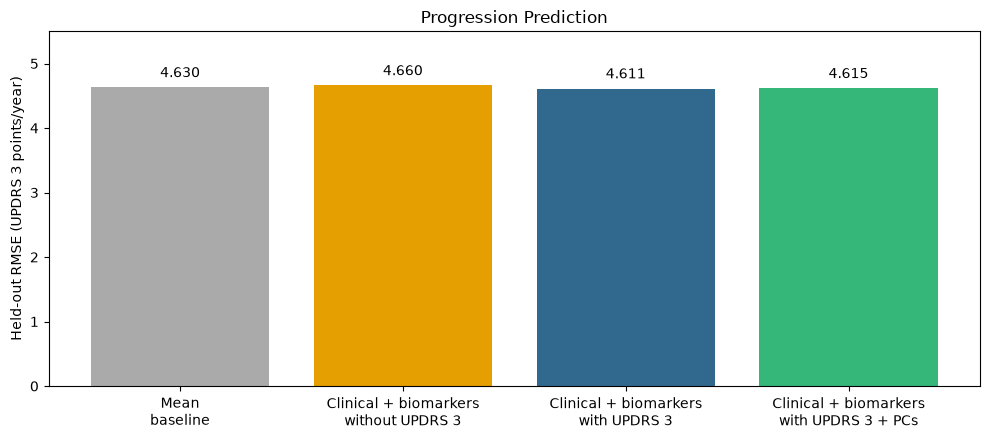

In [43]:
plt.figure(figsize=(10, 4.5))
labels = ["Mean\nbaseline", "Clinical + biomarkers\nwithout UPDRS 3", "Clinical + biomarkers\nwith UPDRS 3", "Clinical + biomarkers\nwith UPDRS 3 + PCs"]
bars = plt.bar(labels, results["RMSE"], color=["#aaaaaa", "#e69f00", "#31688e", "#35b779"])
plt.bar_label(bars, fmt="%.3f", padding=5)
plt.ylim(0, results["RMSE"].max() * 1.18)
plt.ylabel("Held-out RMSE (UPDRS 3 points/year)")
plt.title("Progression Prediction")
plt.tight_layout()
plt.show()

In [44]:
# Predict current severity (baseline UPDRS 1-3) instead of the slope, without any UPDRS score as a predictor.
# UPDRS 4 is left out because most PD participants have no baseline value.
scores = {"UPDRS 1": "updrs1_score", "UPDRS 2": "updrs2_score", "UPDRS 3": "updrs3_score"}
severity_names = ["Mean baseline", "Clinical + biomarkers", "Clinical + biomarkers + PCs"]
severity_results = []

for score_name, score in scores.items():
    has_score = sample[score].notna().to_numpy()
    severity = sample.loc[has_score, score].reset_index(drop=True)
    severity_clinical = clinical_without_updrs[has_score].reset_index(drop=True)
    severity_proteins = sample.loc[has_score, proteins].reset_index(drop=True)
    severity_predictions = pd.DataFrame(index=severity.index, columns=severity_names, dtype=float)

    for train, test in folds.split(severity_clinical):
        imputer, scaler = SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
        clinical_train = scaler.fit_transform(imputer.fit_transform(severity_clinical.iloc[train]))
        clinical_test = scaler.transform(imputer.transform(severity_clinical.iloc[test]))

        protein_train, protein_test = severity_proteins.iloc[train], severity_proteins.iloc[test]
        keep = protein_train.columns[protein_train.isna().mean() <= 0.20]
        imputer, scaler, pca = SimpleImputer(strategy="median"), StandardScaler(), PCA(n_components=3, svd_solver="full")
        pcs_train = pca.fit_transform(scaler.fit_transform(imputer.fit_transform(protein_train[keep])))
        pcs_test = pca.transform(scaler.transform(imputer.transform(protein_test[keep])))

        severity_predictions.loc[test, "Mean baseline"] = severity.iloc[train].mean()
        model = LinearRegression().fit(clinical_train, severity.iloc[train])
        severity_predictions.loc[test, "Clinical + biomarkers"] = model.predict(clinical_test)
        model = LinearRegression().fit(np.column_stack([clinical_train, pcs_train]), severity.iloc[train])
        severity_predictions.loc[test, "Clinical + biomarkers + PCs"] = model.predict(np.column_stack([clinical_test, pcs_test]))

    for name in severity_names:
        severity_results.append({"Score": score_name, "Model": name, "Participants": len(severity),
                                 "RMSE": mean_squared_error(severity, severity_predictions[name]) ** 0.5,
                                 "R²": r2_score(severity, severity_predictions[name])})

severity_results = pd.DataFrame(severity_results).set_index(["Score", "Model"])
severity_results.round(3)

Participants   RMSE     R²
Score   Model                                                  
UPDRS 1 Mean baseline                         817  4.412 -0.003
        Clinical + biomarkers                 817  4.205  0.089
        Clinical + biomarkers + PCs           817  4.217  0.084
UPDRS 2 Mean baseline                         817  4.397 -0.000
        Clinical + biomarkers                 817  4.206  0.085
        Clinical + biomarkers + PCs           817  4.221  0.078
UPDRS 3 Mean baseline                         810  9.804 -0.003
        Clinical + biomarkers                 810  9.472  0.064
        Clinical + biomarkers + PCs           810  9.476  0.063

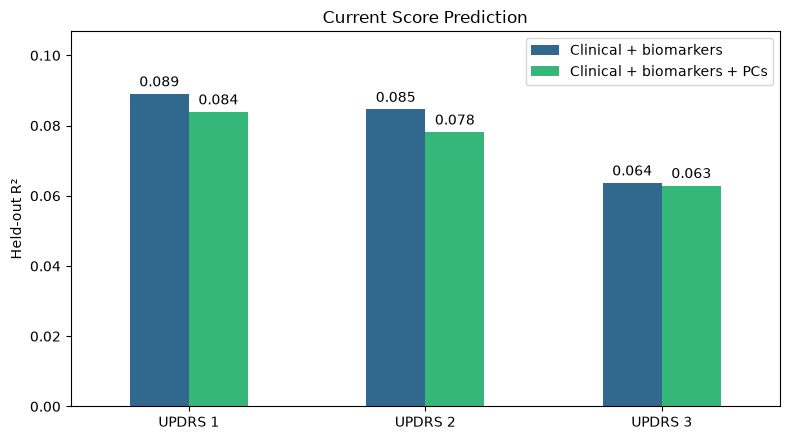

In [45]:
r2 = severity_results["R²"].unstack()[["Clinical + biomarkers", "Clinical + biomarkers + PCs"]]
ax = r2.plot.bar(figsize=(8, 4.5), color=["#31688e", "#35b779"], rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(min(0, r2.min().min()), r2.max().max() * 1.2)
ax.set_xlabel("")
ax.set_ylabel("Held-out R²")
ax.set_title("Current Score Prediction")
ax.legend(title=None)
plt.tight_layout()
plt.show()

## Results

- 819 PD participants had baseline CSF proteins and a progression slope. The median slope was 1.64 points/year.
- RMSE was 4.630 for the mean, 4.611 for clinical variables and biomarkers, and 4.615 with protein PCs. 
- Adding the three protein PCs did not improve prediction in this analysis.
- Current scores are partially predictable. 

## Limitations

- Slopes may be too noisy to enable prediction (clinical visit counts and follow-up lengths are unavailable).
- Baseline UPDRS 3 also contributes to the slope.
- This is internal validation using three PCs. It does not rule out useful signals in individual proteins or other PCs.